In [5]:
import numpy as np
import matplotlib.pyplot as plt
import numpy.random as rdm

from matplotlib import cm

%matplotlib inline

In [8]:
def hinton(matrix, xlabel = None, ylabel = None, max_weight=None, ax=None):
    """Draw Hinton diagram for visualizing a weight matrix."""
    ax = ax if ax is not None else plt.gca()
    print(matrix.shape)
    if not max_weight:
        max_weight = 2 ** np.ceil(np.log2(np.abs(matrix).max()))

    ax.patch.set_facecolor('gray')
    ax.set_aspect('equal', 'box')
    ax.xaxis.set_major_locator(plt.NullLocator())
    ax.yaxis.set_major_locator(plt.NullLocator())

    for (x, y), w in np.ndenumerate(matrix):
        color = 'white' if w > 0 else 'black'
        size = np.sqrt(abs(w) / max_weight)
        rect = plt.Rectangle([x - size / 2, y - size / 2], size, size,
                             facecolor=color, edgecolor=color)
        ax.add_patch(rect)

    if xlabel:
        ax.set_xticks(np.arange(matrix.shape[0]))
        ax.set_xticklabels(xlabel)
    if ylabel:
        ax.set_yticks(np.arange(matrix.shape[1]))
        ax.set_yticklabels(ylabel)
    ax.autoscale_view()
    ax.invert_yaxis()

[8, 10, 6, 7, 11, 5]


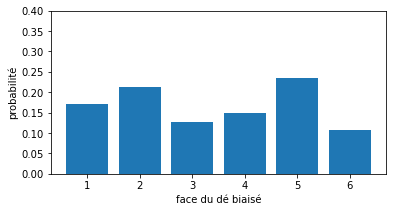

In [9]:
# lancé de dés biaisé
de = np.append(np.append(rdm.randint(1, 7, 40), 5*np.ones(5)), 2*np.ones(2))
p =[]
for k in range(6):
    p.append(len(np.where(de == k+1)[0]))
print(p)
p = np.array(p)/47
plt.figure(figsize=(6,3))
k = np.arange(1,7)
plt.bar(k,p)
plt.xlabel('face du dé biaisé')
plt.ylabel('probabilité')
plt.ylim([0, 0.4])
plt.show()

6 6
[0.17021277 0.38297872 0.5106383  0.65957447 0.89361702 1.        ]


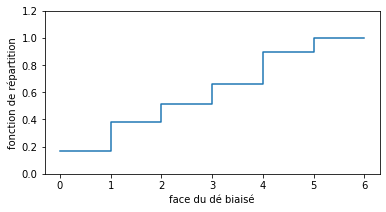

In [11]:
plt.figure(figsize=(6,3))
kc = []
pc =[]

pcum = np.cumsum(p)
print(len(k), len(pcum))
for i in k:
    kc.append(i-1)
    pc.append(pcum[i-1])
    kc.append(i)
    pc.append(pcum[i-1])

print(pcum)
plt.plot(kc, pc)
plt.xlabel('face du dé biaisé')
plt.ylabel('fonction de répartition')
plt.ylim([0, 1.2])
plt.show()

(6, 1)


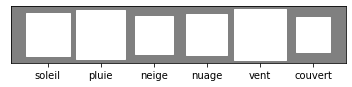

In [12]:
hinton(p.reshape(p.shape[0],1), xlabel= ['soleil', 'pluie', 'neige', 'nuage', 'vent', 'couvert'])

### Densité de probabilité (va continue)
$f(x) = \dfrac{dF_X}{dx}(x)$

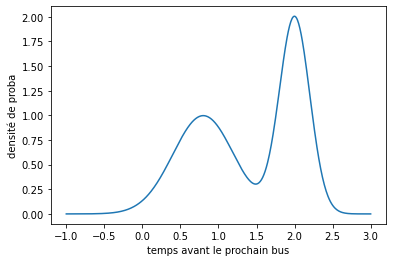

In [21]:
vac = rdm.normal(2, .2, 500) + rdm.normal(.8, .4, 500)
x = np.linspace(-1, 3, 500)
#fvac = 1/np.sqrt(2*np.pi*.04)*np.exp(-(x-2)**2/(2 *.04)) + 1/np.sqrt(2*np.pi*.4*.4)*np.exp(-(x-.8)**2/(2 *.4*.4))
#plt.hist(vac, bins = 10, density = True)
plt.plot(x, fvac)
#plt.hist(vac, bins=40)
plt.xlabel('temps avant le prochain bus')
plt.ylabel('densité de proba')
plt.show()

### Fonction de répartition
comprise en 0 et 1
$F_X(x) = P(X \leq x) = \int_{-\infty}^x f(u)du$

In [ ]:
Fvac = np.cumsum(fvac)
plt.plot(x, Fvac/Fvac[-1])
plt.xlabel('temps avant le prochain bus')
plt.ylabel('fonction de répartition')
plt.show()

## Probabilité jointe
On génère deux entiers correspondant aux faces de deux dés.

Distribution de probabilité si :
* $(X,Y)$ est le couple des deux faces, par exemple (1,2), (3,3), (2,1)
* $(X,Y)$ est le couple avec $X$ le plus grand nombre $Y$ le plus petit

In [ ]:
de2 = rdm.randint(1, 7, (500,2))
p2 = np.zeros((6,6))
for k in range(6):
    for n in range(0,k+1):
        p2[k,n] = len(np.where((de2[:,0] == k+1) & (de2[:,1] == n+1))[0])
print(p2)
labx = ['x'+str(s+1) for s in range(6)]
laby = ['y'+str(s+1) for s in range(6)]
hinton(p2, xlabel = labx, ylabel = laby)
#p = np.array(p)/200


### densité de probabilité pour un couple de va continues


In [22]:
def surface(x,y,z,titre = None):
    fig = plt.figure()
    axes = fig.add_subplot(projection='3d')
    Gx, Gy = np.gradient(z) # gradients with respect to x and y
    G = (Gx**2+Gy**2)**.5  # gradient magnitude
    N = G/G.max()  # normalize 0..1
    axes.plot_surface(
        x, y, z, rstride=1, cstride=1,
        facecolors=cm.jet(N),
        linewidth=0, antialiased=False, shade=False)
    if titre:
        axes.set_title(titre)
    #plt.show()

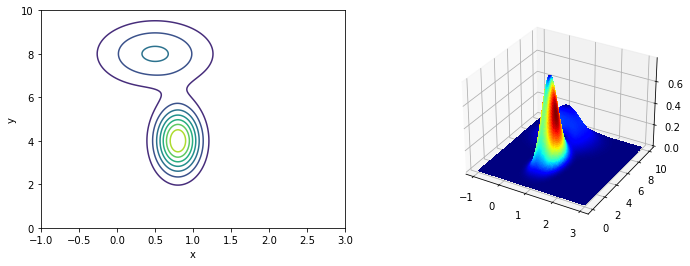

In [23]:
x0 = np.linspace(-1, 3, 500)
y0 = np.linspace(0, 10, 500)
x,y = np.meshgrid(x0,y0)
fxy = 1/(2*np.pi*.2*1)*np.exp(-(((x-.8)/.2)**2 + ((y-4)/1)**2) /2) + 1/(2*np.pi*.5*1)*np.exp(-(((x-.5)/.5)**2 + ((y-8)/1)**2) /2)

fig = plt.figure(figsize =(12,4))
ax1 = fig.add_subplot(121)
ax1.contour(x, y, fxy)
plt.xlabel('x')
plt.ylabel('y')

ax2 = fig.add_subplot(122, projection='3d')
Gx, Gy = np.gradient(fxy) # gradients with respect to x and y
G = (Gx**2+Gy**2)**.5  # gradient magnitude
N = G/G.max()  # normalize 0..1
ax2.plot_surface(
    x, y, fxy, rstride=1, cstride=1,
    facecolors=cm.jet(N),
    linewidth=0, antialiased=False, shade=False)

plt.show()

### Lois marginales suivant x ou y

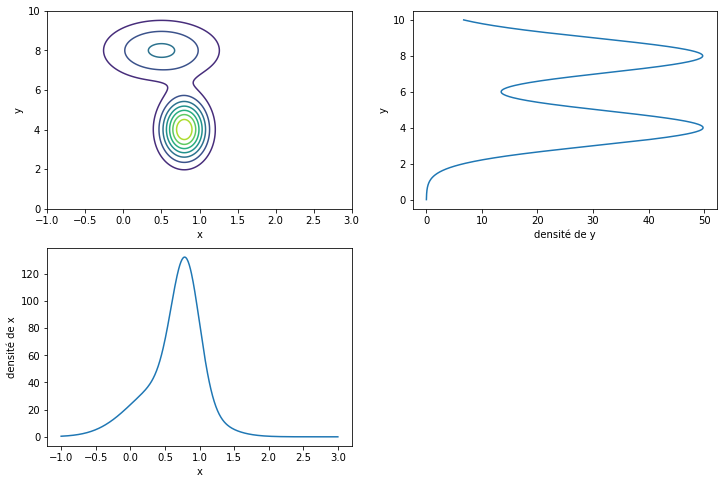

In [24]:
px = np.sum(fxy, axis = 0)
py = np.sum(fxy, axis = 1)

fig = plt.figure(figsize =(12,8))
ax1 = fig.add_subplot(221)
ax1.contour(x, y, fxy)
plt.xlabel('x')
plt.ylabel('y')

ax2 = fig.add_subplot(223)
ax2.plot(x0, px)
ax2.set_xlabel('x')
ax2.set_ylabel('densité de x')

ax3 = fig.add_subplot(222)
ax3.plot(py, y0)
ax3.set_xlabel('densité de y')
ax3.set_ylabel('y')

plt.show()

### Proba conditionnelles -> vue en coupe

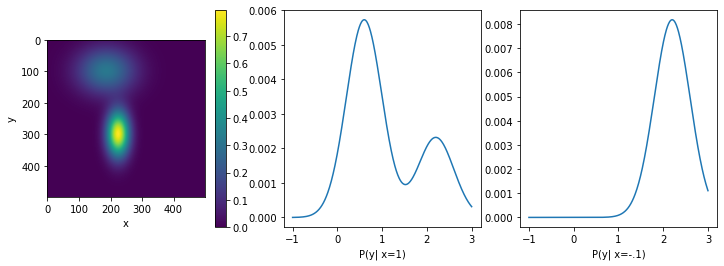

In [25]:
ax60 = fxy[:,250]/fxy[:,250].sum()
ax30 = fxy[:,400]/fxy[:,400].sum()

fig = plt.figure(figsize =(12,4))
ax1 = fig.add_subplot(131)
im = ax1.imshow(np.fliplr(np.flip(fxy)))
#ax1.plot(y0, np.ones(500), color='black')
plt.colorbar(im, ax=ax1)
plt.xlabel('x')
plt.ylabel('y')

ax2 = fig.add_subplot(132)
ax2.plot(x0, ax60)
ax2.set_xlabel('P(y| x=1)')

ax3 = fig.add_subplot(133)
ax3.plot(x0, ax30)
ax3.set_xlabel('P(y| x=-.1)')


plt.show()

### variables discretes indépendantes

In [ ]:
n1 = rdm.binomial(4, .3, 500)
n2 = rdm.binomial(10, .5, 500)
print(n1.max(), n2.max())
p3 = np.zeros((4,10))
for k in range(4):
    for n in range(0,10):
        p3[k,n] = len(np.where((n1 == k+1) & (n2 == n+1))[0])
print(p3)
labx = ['x'+str(s+1) for s in range(4)]
laby = ['y'+str(s+1) for s in range(10)]


hinton(p3, xlabel = labx, ylabel = laby)
plt.figure()
hinton(p3[:, 3].reshape(4,1), xlabel = labx)
plt.title('P(x | y = 3)')
plt.figure()
hinton(p3[:, 6].reshape(4,1), xlabel = labx)
plt.title('P(x | y = 6)')